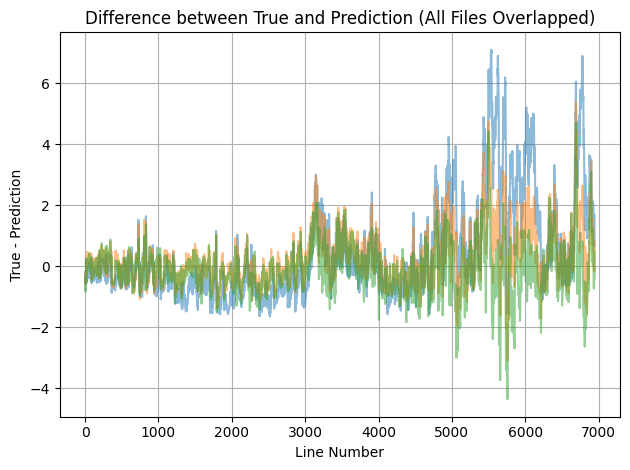

In [38]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Set the folder path
folder_path = '.'  # <- Change this to your folder

for filename in os.listdir(folder_path):
    if filename.endswith('.csv') and 'results' in filename:
        file_path = os.path.join(folder_path, filename)
        try:
            df = pd.read_csv(file_path, header=None)

            # Try to convert both columns to float (handles string numbers)
            df[0] = pd.to_numeric(df[0], errors='coerce')
            df[1] = pd.to_numeric(df[1], errors='coerce')

            # Drop rows with NaN after conversion
            df.dropna(inplace=True)

            if df.shape[1] == 2:
                difference = df[0] - df[1]
                plt.plot(difference.values, alpha=0.5)
        except Exception as e:
            print(f"Skipping {filename}: {e}")

# Final plot
plt.title("Difference between True and Prediction (All Files Overlapped)")
plt.xlabel("Line Number")
plt.ylabel("True - Prediction")
plt.grid(True)
plt.tight_layout()
plt.show()


Interesting, ~3000 is mid Nov where temp begin to drop
~5000 is 12 Dec where temp drop hugely too, first wind of winter? 
~5500 is 16 Dec where temp diff is also huge

=> huge temp drop (compare to when?) cause loss spike

In [5]:
import os
import pandas as pd
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Set the directory containing the CSV files
directory = '.'

# Prepare a list to collect results
results = []

# Iterate over CSV files with "results" in the filename
for filename in os.listdir(directory):
    if filename.endswith('.csv') and 'results' in filename:
        file_path = os.path.join(directory, filename)
        try:
            df = pd.read_csv(file_path, header=None)
            df.columns = ['true', 'pred']
            df['true'] = pd.to_numeric(df['true'], errors='coerce')
            df['pred'] = pd.to_numeric(df['pred'], errors='coerce')
            df = df.dropna()

            mse = mean_squared_error(df['true'], df['pred'])
            mae = mean_absolute_error(df['true'], df['pred'])
            rmse = np.sqrt(mse)
            r2 = r2_score(df['true'], df['pred'])
            results.append({'file': filename, 'MSE': mse, 'MAE': mae, 'RMSE': rmse, 'R2': r2})
        except Exception as e:
            results.append({'file': filename, 'MSE': None, 'MAE': None, 'RMSE': None, 'R2': None, 'Error': str(e)})

# Convert the results to a DataFrame
results_df = pd.DataFrame(results)
display(results_df)

,file,MSE,MAE,RMSE,R2
0,results_trial_2_seed_6909.csv,2.869343,1.151127,1.693913,0.317486
1,results_trial_3_seed_2788.csv,0.672409,0.608537,0.820005,0.840058
2,results_trial_1_seed_9970.csv,0.846164,0.652937,0.919872,0.798728
3,results_trial_0_seed_689.csv,0.661120,0.592366,0.813093,0.842743
4,results_trial_4_seed_6118.csv,0.880916,0.668454,0.938571,0.790462
